# Vehicle insurance claims: does a decision model make XGBoost better at spotting fraud?

We compare three ways of scoring auto insurance claims for fraud, on Oracle's public
[CLAIMS](https://github.com/AnalyticsandDataOracleUserCommunity/MachineLearning/tree/master/claims) data:

| Approach | What it uses |
| --- | --- |
| **XGBoost** | The 27 fields of each claim |
| **XGBoost + Jev** | The same, plus Jev's (TypeSafe) answers to 8 yes/no questions about each claim |
| **XGBoost + Grayson** | The same, plus Grayson's (Finic) answers to the same 8 questions |

Jev and Grayson never see whether a claim was fraud; only XGBoost learns from the labels. The metric is
ROC-AUC (0.5 is chance, 1.0 is perfect), from repeated cross-validation over all claims.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from scipy.stats import ttest_rel
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, train_test_split

from fraudbench import api, data
from fraudbench import questions as qmod

# API keys come from the environment or a git-ignored .env file. Without them, cached answers are used.
if Path(".env").exists():
    for line in Path(".env").read_text().splitlines():
        k, sep, v = line.partition("=")
        if sep and not line.lstrip().startswith("#"):
            os.environ.setdefault(k.strip(), v.strip().strip('"'))

SEED = 2026
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:.4f}".format)

## 1. Data

1,782 auto insurance claims from a US insurer (1994–96), 923 of them fraud. Each claim has 27 fields:
accident timing, vehicle, policyholder, policy and claim circumstances, mostly pre-binned (e.g. age
`26to30`). The notebook downloads `CLAIMS.csv` on first run.

The extract is 52% fraud, far above a real insurer's rate. ROC-AUC does not depend on that mix, so we
use the claims as given. Only the ROI in section 4 needs a real-world rate: policy numbers run from 1
to 15,420 and the extract holds 923 fraud claims, so we take 923 ÷ 15,420 ≈ 6%.

In [2]:
df = data.assign_split(data.load(), seed=SEED)
by_id = df.set_index("id")
ids = {s: df.loc[df.split == s, "id"].values for s in ("train", "val", "test")}
y = df[data.LABEL].values
X = data.xgb_features(df).values
print(f"{len(df):,} claims, {y.sum()} fraud ({y.mean():.0%})")

1,782 claims, 923 fraud (52%)


## 2. The questions and the API answers

The 8 questions were chosen from the 1,069 claims of a fixed training split: each candidate is kept if
the claims it describes are at least 10% more likely to be fraud than average, and the direct question
"Is this record fraudulent?" is always included. The list is frozen in `data/questions.json`.

Every claim goes to Grayson and Jev once, with all its fields except the label and policy number, and
the same 8 questions. Each answer is a probability; as log-odds, the 8 answers become 8 extra input
columns for XGBoost.

In [3]:
if qmod.QUESTIONS_PATH.exists():
    QUESTIONS = qmod.load()
else:
    train = df[df.split == "train"]
    QUESTIONS = qmod.freeze(qmod.lift_table(train, data.candidates(train), data.LABEL, min_lift=1.10, min_support=0.02))
pd.Series(QUESTIONS, name="question").to_frame()

,question
young_policyholder,Is the policyholder 25 or younger?
address_changed,Did the address change shortly before the claim?
covers_own_vehicle,Does the policy cover damage to the policyhold...
first_claim,Is this the policyholder's first claim?
old_for_price,Is the vehicle old relative to its price band?
rural_accident,Did the accident happen in a rural area?
at_fault,Was the policyholder at fault?
is_fraud,Is this record fraudulent?


In [4]:
def logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p))

contexts = {s: {int(i): data.build_context(by_id.loc[i]) for i in ids[s]} for s in ids}
FEATURES = {"XGBoost": X}
for client, label in ((api.Jev(), "XGBoost + Jev"), (api.Grayson(), "XGBoost + Grayson")):
    answers = pd.concat([api.query(client, contexts[s], QUESTIONS, s) for s in ids]).loc[df["id"].values]
    FEATURES[label] = np.hstack([X, logit(answers.values)])
{label: F.shape for label, F in FEATURES.items()}

{'XGBoost': (1782, 27),
 'XGBoost + Jev': (1782, 35),
 'XGBoost + Grayson': (1782, 35)}

## 3. Results

Each approach is the same XGBoost search (depth 2, 3 or 4; trees chosen by early stopping on an inner
25% split). It is scored out-of-fold on all 1,782 claims with 12 repeats of 5-fold cross-validation and
compared with plain XGBoost repeat by repeat. The repeats reuse the same claims, so read the p-value as
a guide.

In [5]:
def fit_xgb(F, tr, te, seed):
    fit, es = train_test_split(tr, test_size=0.25, stratify=y[tr], random_state=seed)
    best = None
    for depth in (2, 3, 4):
        m = xgb.XGBClassifier(n_estimators=2000, learning_rate=0.03, max_depth=depth, subsample=0.8,
                              colsample_bytree=0.8, eval_metric="aucpr", early_stopping_rounds=100, random_state=seed)
        m.fit(F[fit], y[fit], eval_set=[(F[es], y[es])], verbose=False)
        score = average_precision_score(y[es], m.predict_proba(F[es])[:, 1])
        if best is None or score > best[0]:
            best = (score, depth, m.best_iteration + 1)
    m = xgb.XGBClassifier(n_estimators=best[2], learning_rate=0.03, max_depth=best[1], subsample=0.8,
                          colsample_bytree=0.8, random_state=seed)
    return m.fit(F[tr], y[tr]).predict_proba(F[te])[:, 1]

REPEATS = 12
cv_oof = []
for r in range(REPEATS):
    oof = {label: np.zeros(len(y)) for label in FEATURES}
    for k, (tr, te) in enumerate(StratifiedKFold(5, shuffle=True, random_state=SEED + 1000 + r).split(X, y)):
        for label, F in FEATURES.items():
            oof[label][te] = fit_xgb(F, tr, te, SEED + 100 * r + k)
    cv_oof.append(oof)

auc = pd.DataFrame([{label: roc_auc_score(y, p) for label, p in o.items()} for o in cv_oof])
results = pd.DataFrame({
    "ROC-AUC": auc.mean(),
    "vs XGBoost": auc.mean() - auc["XGBoost"].mean(),
    "repeats better than XGBoost": auc.gt(auc["XGBoost"], axis=0).sum(),
    "paired t-test p": {c: ttest_rel(auc[c], auc["XGBoost"]).pvalue if c != "XGBoost" else np.nan for c in auc},
})
results.to_csv(RESULTS / "results.csv")
results

,ROC-AUC,vs XGBoost,repeats better than XGBoost,paired t-test p
XGBoost,0.7984,0.0000,0,NaN
XGBoost + Jev,0.7959,-0.0025,4,0.3356
XGBoost + Grayson,0.8050,0.0066,10,0.0556


## 4. What it is worth

An insurer sends a fixed share of claims to its investigators, riskiest first. At the same workload, a
better ranking catches more fraud. Below: the extra fraud caught per year by each approach compared
with plain XGBoost, at a real-world fraud rate of ~6%, for an insurer with 100,000 claims a year. The
dollar figures assume a $5,000 average claim and that half of a caught fraudulent claim's value is
saved; the data has no claim amounts, so treat them as illustrative.

In [6]:
CLAIMS_PER_YEAR, AVG_CLAIM, SHARE_SAVED = 100_000, 5_000, 0.5
# Reweight the 52% extract to a ~6% fraud rate: each legitimate claim counts for ~16.9.
weights = np.where(y == 1, 1.0, y.sum() * (1 - data.TRUE_RATE) / ((y == 0).sum() * data.TRUE_RATE))
fraud_per_year = CLAIMS_PER_YEAR * data.TRUE_RATE

def fraud_caught(p, share):
    order = np.argsort(-p)
    reviewed = order[np.cumsum(weights[order]) / weights.sum() <= share]
    return y[reviewed].sum() / y.sum()

rows = []
for share in (0.05, 0.10, 0.20):
    base = np.array([fraud_caught(o["XGBoost"], share) for o in cv_oof])
    for label in ("XGBoost + Jev", "XGBoost + Grayson"):
        gain = np.mean([fraud_caught(o[label], share) for o in cv_oof]) - base.mean()
        rows.append({"claims reviewed": f"{share:.0%}", "approach": label,
                     "extra frauds caught / year": gain * fraud_per_year,
                     "savings / year ($)": gain * fraud_per_year * AVG_CLAIM * SHARE_SAVED})
roi = pd.DataFrame(rows).set_index(["claims reviewed", "approach"])
roi.to_csv(RESULTS / "roi.csv")
roi.round().astype(int)

extra frauds caught / year  \
claims reviewed approach                                        
5%              XGBoost + Jev                             -34   
                XGBoost + Grayson                         106   
10%             XGBoost + Jev                             -25   
                XGBoost + Grayson                         165   
20%             XGBoost + Jev                             -90   
                XGBoost + Grayson                          55   

                                   savings / year ($)  
claims reviewed approach                               
5%              XGBoost + Jev                  -83766  
                XGBoost + Grayson              266159  
10%             XGBoost + Jev                  -63500  
                XGBoost + Grayson              412073  
20%             XGBoost + Jev                 -224276  
                XGBoost + Grayson              136457

## 5. ROC curves

Out-of-fold predictions from the first repeat; the legend shows the mean ROC-AUC over all 12.

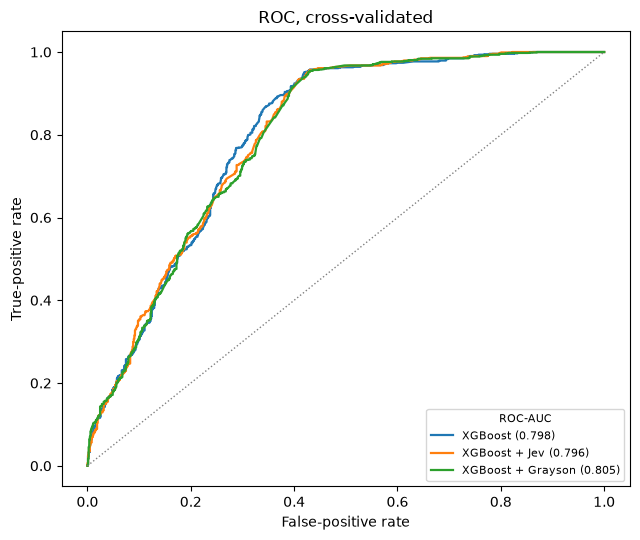

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for label, p in cv_oof[0].items():
    fpr, tpr, _ = roc_curve(y, p)
    ax.plot(fpr, tpr, lw=1.6, label=f"{label} ({results.loc[label, 'ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], color="grey", ls=":", lw=1)
ax.set(xlabel="False-positive rate", ylabel="True-positive rate", title="ROC, cross-validated")
ax.legend(fontsize=8, title="ROC-AUC", title_fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS / "roc.png", dpi=150)